<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
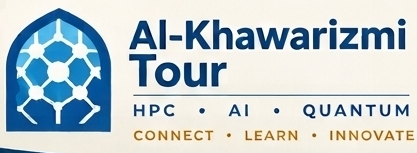
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 1 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Data Quality &amp; Preprocessing — Beijing Air Quality · Hands-on &amp; Week-1 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos used during the lecture (slide references in each heading) · Part B: the week-long <b>Air-Quality Data Challenge</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A11) | during the 2-hour lecture | each demo matches a slide of the deck / a card of the speaker script |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells, write your report, prepare your pitch |

**Dataset:** *Beijing Multi-Site Air Quality* — UCI Machine Learning Repository, dataset 501. Hourly PM2.5, PM10, SO2, NO2, CO, O3 (µg/m³) and TEMP, PRES, DEWP, RAIN, wind direction `wd`, wind speed `WSPM` at **12 stations**, **1 Mar 2013 – 28 Feb 2017**, **420,768 rows**, with real missing values (NA).
Reference: Zhang, S. et al. (2017) *Cautionary tales on air-quality improvement in Beijing*, Proc. R. Soc. A.

**Data access:** the notebook downloads the archive from UCI (≈ 8 MB) and caches it. If you already have the `PRSA_Data_*.csv` files, put them next to the notebook. Offline, a synthetic stand-in with the same columns is generated so the code still runs.

**Requirements:** Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, `scikit-learn ≥ 1.2`. Works in Jupyter, VS Code or Google Colab. Tip: on a laptop, run Part A first on `SAMPLE_STATIONS` (4 stations) and switch to all 12 for the challenge.

## 0 · Setup — set your team number first

In [131]:
TEAM_ID = 1210            # <-- your team number: it seeds YOUR version of the merged dataset
SEED = 1000 + TEAM_ID

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)
import sklearn; print("scikit-learn", sklearn.__version__, "| team", TEAM_ID)

scikit-learn 1.9.1 | team 1210


---
# Part A · Guided demos
## A1 · Load the 12 station files  *(slides 2 & 13)*

In [132]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## A2 · The scenario: a careless merge + an untouched final year  *(slides 27 & 32)*
* **Test year** = 1 Mar 2016 – 28 Feb 2017 (the real data, untouched) — used **only in Task 6**.
* **Training years** = 1 Mar 2013 – 29 Feb 2016 → turned into your team's *merged export* with realistic merge errors.

In [133]:
SPLIT = pd.Timestamp("2016-03-01")
train_raw = raw[raw["datetime"] < SPLIT].reset_index(drop=True)
test_year = raw[raw["datetime"] >= SPLIT].reset_index(drop=True)
print(f"training years: {len(train_raw):,} rows | test year: {len(test_year):,} rows")

training years: 315,648 rows | test year: 105,120 rows


## A3 · Generate your team's merged export
The function reproduces problems of a careless multi-station merge. **Treat it as a black box during the challenge** — your job is to *discover* the problems from the data.

In [134]:
def make_dirty(df, seed):
    r = np.random.default_rng(seed)
    d = df.drop(columns=["datetime"]).copy()
    n = len(d)
    st_unit, st_tz, st_stuck = r.choice(STATIONS, 3, replace=False)
    # 1) consistency: station-name variants and lower-case wind directions
    v = r.random(n)
    d.loc[v < .05, "station"] = d.loc[v < .05, "station"].str.upper()
    d.loc[(v >= .05) & (v < .10), "station"] = d.loc[(v >= .05) & (v < .10), "station"].str.lower() + " "
    w = r.random(n) < .02
    d.loc[w, "wd"] = d.loc[w, "wd"].str.lower()
    stn = d["station"].str.strip().str.title()
    # 2) accuracy: one station exported CO in mg/m3 during 2014
    m = (stn == st_unit) & (d["year"] == 2014)
    d.loc[m, "CO"] = d.loc[m, "CO"] / 1000
    # 3) timeliness: one station exported in UTC during 2015 (8 h behind Beijing time)
    m = (stn == st_tz) & (d["year"] == 2015)
    dt = pd.to_datetime(d.loc[m, ["year", "month", "day", "hour"]]) - pd.Timedelta(hours=8)
    d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: stuck PM2.5 sensor (flat lines), sentinel codes, PM2.5/PM10 column swap
    idx = np.flatnonzero((stn == st_stuck).values)
    for s0 in r.choice(idx[:-80], 8, replace=False):
        L = int(r.integers(24, 73)); rows = d.index[s0:s0 + L]
        d.loc[rows, "PM2.5"] = d.loc[rows[0], "PM2.5"]
    for c in ["TEMP", "PRES"]:
        d.loc[r.random(n) < .002, c] = -999
    sw = r.random(n) < .003
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) completeness: extra random logger drop-outs in NO2
    d.loc[r.random(n) < .03, "NO2"] = np.nan
    # 6) uniqueness: one station-month re-uploaded (slightly different O3) + scattered exact duplicates
    s_dup = r.choice(STATIONS); y_dup, m_dup = 2014, int(r.integers(1, 13))
    re = d[(stn == s_dup) & (d["year"] == y_dup) & (d["month"] == m_dup)].copy()
    re["O3"] = re["O3"] + 1
    d = pd.concat([d, re, d.sample(frac=.005, random_state=seed)], ignore_index=True)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

dirty = make_dirty(train_raw, SEED)
dirty.to_csv(f"beijing_merged_team{TEAM_ID}.csv.gz", index=False)
print(f"merged export: {dirty.shape[0]:,} rows -> beijing_merged_team{TEAM_ID}.csv.gz")
dirty.head()

merged export: 317,970 rows -> beijing_merged_team1210.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,4980,2013,9,24,11,8.0,12.0,6.0,28.0,400.0,31.0,20.0,1014.7,3.6,0.0,NW,1.4,Gucheng
1,1773,2013,5,13,20,145.0,268.0,80.0,66.0,2700.0,150.0,22.0,997.9,9.8,0.0,ENE,1.8,Dongsi
2,20660,2015,7,9,19,39.0,41.0,7.0,26.0,700.0,215.0,30.9,1006.8,13.7,0.0,SE,2.9,Nongzhanguan
3,11720,2014,7,2,7,53.0,53.0,2.0,22.0,900.0,95.0,21.2,999.9,20.7,1.7,ENE,1.1,Nongzhanguan
4,19135,2015,5,7,6,23.0,87.0,2.0,19.0,400.0,31.0,10.5,1002.0,-4.0,0.0,NNW,1.2,Dingling


## A4 · First look  *(slides 11, 13 & 14)*

In [135]:
df = dirty.copy()
print("shape:", df.shape, "\n")
print(df.dtypes, "\n")
print("fraction missing:\n", df.isna().mean().round(4).sort_values(ascending=False), "\n")
print("duplicate station-hours:", df.duplicated(subset=KEY).sum())
print("station labels:", df["station"].nunique(), "distinct (expected 12)")

shape: (317970, 18) 

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object 

fraction missing:
 NO2        0.0596
CO         0.0573
O3         0.0322
SO2        0.0221
PM2.5      0.0202
PM10       0.0146
wd         0.0021
RAIN       0.0006
DEWP       0.0006
PRES       0.0006
WSPM       0.0006
TEMP       0.0006
year       0.0000
No         0.0000
day        0.0000
month      0.0000
hour       0.0000
station    0.0000
dtype: float64 

duplicate station-hours: 2330
station labels: 36 distinct (expected 12)


In [136]:
# mean vs median per station -> skew; min / max -> impossible values
df.groupby(df["station"].str.strip().str.title())[["PM2.5", "CO", "TEMP", "PRES"]].agg(["mean", "median", "min", "max"]).round(1)

PM2.5                         CO                          TEMP  \
               mean median  min    max    mean  median    min      max  mean   
station                                                                        
Aotizhongxin   83.6   60.0  3.0  898.0  1272.5   900.0  100.0  10000.0  11.3   
Changping      72.5   47.0  2.0  882.0  1145.9   800.0  100.0  10000.0  11.3   
Dingling       66.8   41.0  3.0  881.0   603.5   300.0    0.1   9400.0  11.8   
Dongsi         85.7   61.0  3.0  737.0  1340.0  1000.0  100.0  10000.0  11.2   
Guanyuan       82.9   60.0  3.0  680.0  1290.1   900.0  100.0  10000.0  11.5   
Gucheng        83.9   61.0  2.0  770.0  1354.6  1000.0  100.0   9900.0  11.8   
Huairou        71.2   48.0  2.0  762.0  1035.7   800.0  100.0  10000.0  10.8   
Nongzhanguan   85.5   60.0  3.0  844.0  1335.9  1000.0  100.0  10000.0  12.0   
Shunyi         80.6   56.0  3.0  941.0  1180.6   900.0  100.0  10000.0  11.7   
Tiantan        82.9   60.0  3.0  821.0  1307.8  1000.0  100.0  10000.0  11.7   
Wanliu         85.4   61.0  3.0  957.0  1335.9   900.0  100.0  10000.0  10.7   
Wanshouxigong  84.8   61.0  3.0  999.0  1395.6  1000.0  100.0   9800.0  11.5   

                                     PRES                         
              median    min   max    mean  median    min     max  
station                                                           
Aotizhongxin    14.3 -999.0  40.5  1007.1  1011.2 -999.0  1042.0  
Changping       14.6 -999.0  41.4  1003.1  1007.5 -999.0  1036.5  
Dingling        14.6 -999.0  41.4  1003.1  1007.5 -999.0  1036.5  
Dongsi          14.5 -999.0  41.1  1008.5  1012.2 -999.0  1042.0  
Guanyuan        14.3 -999.0  40.5  1007.8  1011.2 -999.0  1042.0  
Gucheng         14.8 -999.0  41.6  1005.2  1008.6 -999.0  1038.1  
Huairou         13.4 -999.0  40.3  1003.1  1007.3 -999.0  1036.5  
Nongzhanguan    14.5 -999.0  41.1  1009.0  1012.3 -999.0  1042.0  
Shunyi          14.9 -999.0  40.6  1008.3  1012.2 -999.0  1042.8  
Tiantan         14.5 -999.0  41.1  1008.9  1012.3 -999.0  1042.0  
Wanliu          14.2 -999.0  40.5  1007.6  1010.9 -999.0  1040.3  
Wanshouxigong   14.7 -999.0  40.6  1007.9  1010.6 -999.0  1042.0

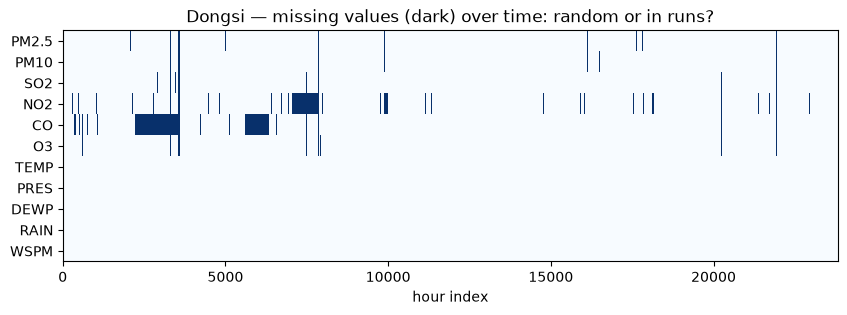

In [137]:
# missing-value matrix for one station (rows = hours in time order)
one = df[df["station"] == "Dongsi"].sort_values(["year", "month", "day", "hour"])
plt.figure(figsize=(10, 3))
plt.imshow(one[POLLUTANTS + WEATHER].isna().values.T, aspect="auto", interpolation="nearest", cmap="Blues")
plt.yticks(range(len(POLLUTANTS + WEATHER)), POLLUTANTS + WEATHER); plt.xlabel("hour index"); plt.grid(False)
plt.title("Dongsi — missing values (dark) over time: random or in runs?"); plt.show()

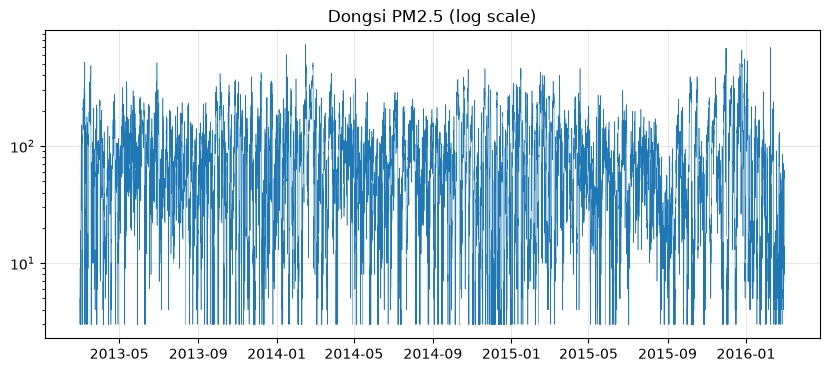

In [138]:
# the single most useful plot: a time series per station
one_dt = pd.to_datetime(one[["year", "month", "day", "hour"]])
plt.plot(one_dt, one["PM2.5"], lw=.4); plt.yscale("log"); plt.title("Dongsi PM2.5 (log scale)"); plt.show()

## A5 · Consistency: canonical labels  *(slide 21)*

In [139]:
print(df["station"].value_counts().head(15))
canon = df["station"].str.strip().str.title()
print("\nafter strip + title:", canon.nunique(), "stations")
print("wind directions:", sorted(df["wd"].dropna().unique()))

station
Shunyi           24501
Changping        23900
Tiantan          23858
Aotizhongxin     23855
Dongsi           23817
Guanyuan         23798
Nongzhanguan     23783
Gucheng          23779
Wanshouxigong    23772
Huairou          23747
Wanliu           23701
Dingling         23603
dingling          1434
wanliu            1411
DINGLING          1393
Name: count, dtype: int64

after strip + title: 12 stations
wind directions: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW', 'e', 'ene', 'ese', 'n', 'ne', 'nne', 'nnw', 'nw', 's', 'se', 'sse', 'ssw', 'sw', 'w', 'wnw', 'wsw']


## A6 · Outliers, stuck sensors and physics checks  *(slides 19 & 20)*

In [140]:
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

PM2.5 > PM10 (impossible)    21942
negative concentrations          0
sentinel -999 codes           1256
PRES outside 950-1060 hPa      632
Name: rows, dtype: int64

In [141]:
def hampel_flags(s, window=25, k=3.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med).abs() > k * 1.4826 * mad

def stuck_flags(s, hours=12):
    return s.rolling(hours).std() == 0

res = {}
for st, g in df.assign(station=canon).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()), "stuck >= 12 h": int(stuck_flags(g["PM2.5"]).sum())}
pd.DataFrame(res).T.sort_values("stuck >= 12 h", ascending=False)

,Hampel spikes,stuck >= 12 h
Nongzhanguan,1188,77
Dongsi,1259,30
Wanshouxigong,1109,23
Huairou,1360,17
Aotizhongxin,1180,1
Changping,1184,0
Dingling,1550,0
Gucheng,1248,0
Guanyuan,1111,0
Shunyi,1289,0


## A7 · Imputation study — single hours vs 24-hour gaps  *(slide 18)*
We hide values we **know** (clean reference = the original training years, demo only) and measure the RMSE of each imputer.

In [142]:
from sklearn.impute import KNNImputer
piv = train_raw.pivot_table(index="datetime", columns="station", values="NO2")   # hours x stations
target_st = "Dongsi"
truth = piv[target_st]
known = np.flatnonzero(truth.notna().values)

def make_mask(kind):
    m = np.zeros(len(truth), bool)
    if kind == "single hours":
        m[rng.choice(known, len(known) // 10, replace=False)] = True
    else:                                                    # 24-h blocks
        for s0 in rng.choice(known[:-30], 150, replace=False):
            m[s0:s0 + 24] = True
        m &= truth.notna().values
    return m

def evaluate(mask):
    s = truth.mask(mask)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.Series(KNNImputer(n_neighbors=5).fit_transform(piv.assign(**{target_st: s}))[:, list(piv.columns).index(target_st)], index=s.index),
    }
    return {k: np.sqrt(np.mean((v.fillna(s.mean()).values[mask] - truth.values[mask]) ** 2)) for k, v in cand.items()}

t0 = time.perf_counter()
study = pd.DataFrame({kind: evaluate(make_mask(kind)) for kind in ["single hours", "24-h blocks"]}).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE of NO2 in µg/m³ — lower is better")
study

(55.4 s)  RMSE of NO2 in µg/m³ — lower is better


,single hours,24-h blocks
mean,33.82,33.71
median,34.21,34.65
time interpolation,7.65,29.01
neighbour stations,13.77,14.62
KNN across stations,9.32,11.53


## A8 · Skewness and transformations  *(slides 12 & 25)*

skewness raw:
 PM2.5    1.93
SO2      2.74
CO       2.45
NO2      1.03
O3       1.75
WSPM     1.67
dtype: float64

skewness after log1p:
 PM2.5   -0.33
SO2      0.42
CO      -0.00
NO2     -0.72
O3      -0.59
WSPM     0.29
dtype: float64


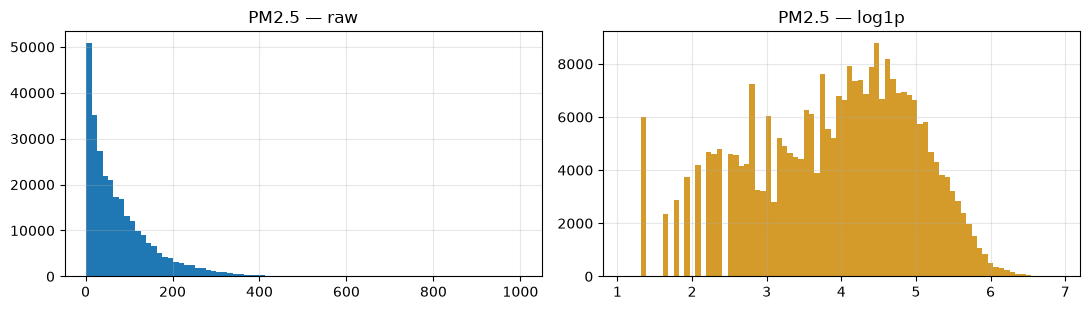

In [143]:
from sklearn.preprocessing import PowerTransformer
vals = train_raw[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
print("skewness raw:\n", vals.skew().round(2))
print("\nskewness after log1p:\n", np.log1p(vals).skew().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals["PM2.5"], bins=80); ax[0].set_title("PM2.5 — raw")
ax[1].hist(np.log1p(vals["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 — log1p")
plt.tight_layout(); plt.show()

## A9 · Multicollinearity — VIF  *(slide 22)*

In [144]:
def vif(frame):
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for c in X.columns:
        Aa = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(Aa, X[c].values, rcond=None)
        resid = X[c].values - Aa @ coef
        out[c] = 1 / max(1 - (1 - (resid ** 2).sum() / ((X[c] - X[c].mean()) ** 2).sum()), 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

vif(train_raw[["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]].dropna().sample(50_000, random_state=0))

TEMP    7.83
DEWP    5.75
PRES    3.14
NO2     2.62
CO      2.52
O3      2.23
SO2     1.83
WSPM    1.60
Name: VIF, dtype: float64

## A10 · Leakage demo — random split vs time split  *(slides 27 & 28)*
Same model, same data, two ways of splitting. The random split lets near-identical neighbouring hours sit on both sides.

In [145]:
def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

def make_pipeline(model):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

ref = add_features(train_raw.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
ref = ref.iloc[::3]                                   # every 3rd hour keeps the demo fast
X_ref, y_ref = ref[NUM_FEATS + CAT_FEATS], ref[TARGET]
hgb = make_pipeline(HistGradientBoostingRegressor(max_iter=200, random_state=0))
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(hgb, X_ref, y_ref, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:16s} CV RMSE = {-s.mean():6.2f} ± {s.std():.2f} µg/m³")

random KFold     CV RMSE =  29.71 ± 0.19 µg/m³
TimeSeriesSplit  CV RMSE =  42.32 ± 10.22 µg/m³


## A11 · Template: a leak-free, time-aware pipeline  *(slide 29)*
`make_pipeline` above is the template you adapt in Task 5. Everything that *learns* (imputers, scalers, encoders) lives **inside** it, so it is re-fitted in every fold.

---
# Part B · Week-1 Team Challenge — *The Air-Quality Data Challenge*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The city’s environmental agency merged the exports of its <b>12 monitoring stations</b> (1 Mar 2013 – 29 Feb 2016) for an AI project. On top of the real gaps, the merge introduced errors. Your file <code>beijing_merged_team&lt;N&gt;.csv.gz</code> (created in A3) is your team’s version. <br><b>Goal:</b> deliver a documented, leak-free pipeline for a <b>virtual PM2.5 sensor</b> — estimate PM2.5 from gases, weather, time and station, <b>without PM10</b> (same instrument, down at the same time) — and <b>prove with numbers</b> how much your data work improves it on the untouched test year.</div>

| # | Task | Points |
|---|---|---|
| 1 | Data-quality audit (six dimensions, gap lengths, missingness by station) | 15 |
| 2 | Consistency, validity & timeliness fixes | 15 |
| 3 | Imputation study (≥ 3 imputers incl. one time-aware) | 15 |
| 4 | Outliers: stuck sensors & spikes vs real episodes; transformations | 10 |
| 5 | Leak-free pipeline + `TimeSeriesSplit` CV | 15 |
| 6 | Impact study on the test year | 20 |
| ★ | HPC bonus: parallel per-station cleaning | +10 |
|   | 1-page report + 5-min pitch | 10 |

**Rules:** `test_year` only in Task 6 · justify every decision in one line · keep `SEED` fixed · start from `beijing_merged_team<N>.csv.gz`, not from `train_raw`.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–5 · Day 5 Task 6 (+ bonus) · Days 6–7 report & pitch.

**Hint — what kinds of problems to look for:** label variants, a unit mix-up, a time-zone shift, re-uploaded data, stuck sensors, sentinel codes, physically impossible values, extra drop-outs. *Which station, which column, which period? That is for you to find.*

## Task 1 · Data-quality audit (15 pts)

percentage of missing data per column is   No          0.000000
year        0.000000
month       0.000000
day         0.000000
hour        0.000000
PM2.5       2.015913
PM10        1.463660
SO2         2.213731
NO2         5.964399
CO          5.734818
O3          3.222946
TEMP        0.056609
PRES        0.056924
DEWP        0.058182
RAIN        0.055666
wd          0.213542
WSPM        0.056295
station     0.000000
datetime    0.000000
dtype: float64
percentage of missing data per station is                    No  year  month  day  hour     PM2.5      PM10       SO2  \
station                                                                     
AOTIZHONGXIN    0.0   0.0    0.0  0.0   0.0  2.329193  2.018634  3.027950   
Aotizhongxin    0.0   0.0    0.0  0.0   0.0  2.846363  2.313980  3.026619   
CHANGPING       0.0   0.0    0.0  0.0   0.0  3.009259  2.314815  2.314815   
Changping       0.0   0.0    0.0  0.0   0.0  2.514644  1.841004  1.820084   
DINGLING        0.0   0.0    0.0  0.0

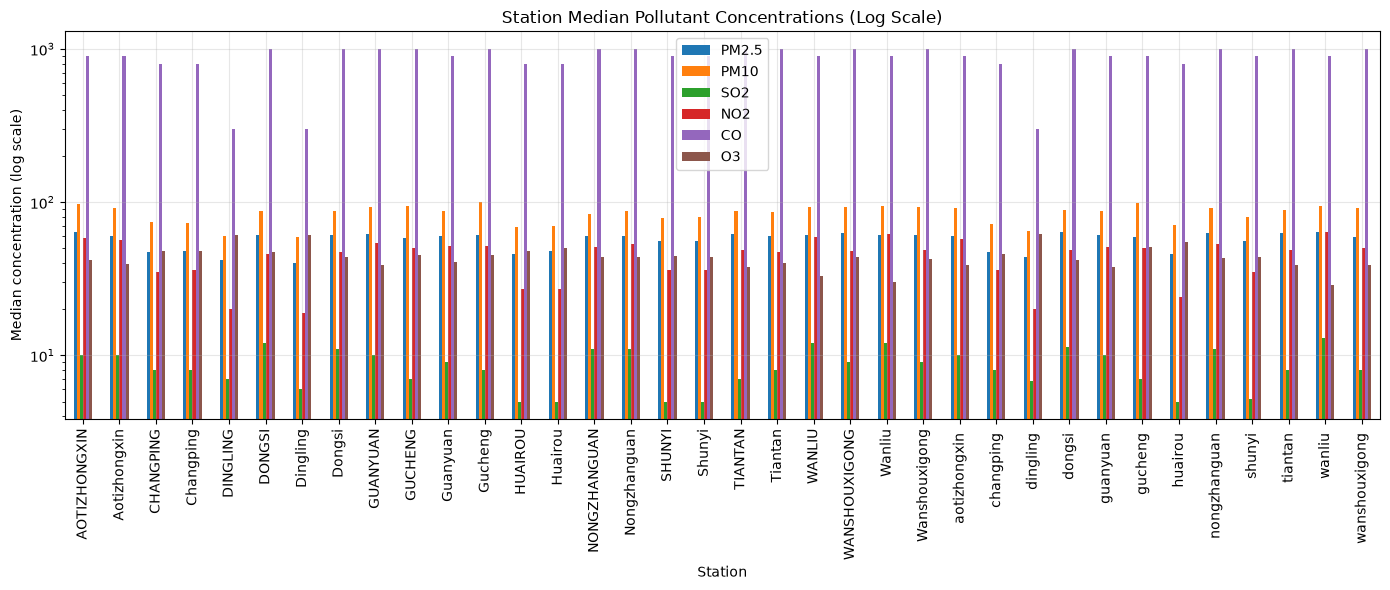


Station medians by year:                      PM2.5   PM10      SO2      NO2      CO       O3
year station                                                        
2013 AOTIZHONGXIN     66.0  105.0  13.0000  63.2324   900.0  40.0000
     Aotizhongxin     61.0   97.0  14.0000  60.0000   900.0  34.0000
     CHANGPING        57.0   76.0  12.0000  34.0000   800.0  49.0000
     Changping        52.0   74.0  10.9264  35.0000   800.0  48.0000
     DINGLING         44.0   55.0   8.0000  24.0000   700.0  51.8111
...                    ...    ...      ...      ...     ...      ...
2016 nongzhanguan     18.0   37.5  10.0000  36.0000   500.0  52.0000
     shunyi           32.0   41.0   9.0000  37.0000   700.0  37.0000
     tiantan          34.5   45.5   8.0000  47.0000   850.0  41.0000
     wanliu           26.5   50.0  15.0000  65.0000  1100.0  18.5000
     wanshouxigong    26.5   49.5  11.5000  32.5000   800.0  44.5000

[144 rows x 6 columns]

Suspicious station-years (ratio to typical station):

In [146]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

TEAM_ID = 1210         # <-- your team number: it seeds YOUR version of the merged dataset

df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

#1a
print("percentage of missing data per column is  " , df.isna().mean()*100)
print("percentage of missing data per station is  " , df.groupby("station").apply(lambda x: x.isna().mean()*100))
d = df.drop_duplicates(["station","datetime"]).sort_values(["station","datetime"])
def gap_lengths(s):
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    return isna.groupby(grp).sum()[isna.groupby(grp).first()]

gaps = d.groupby("station")["PM2.5"].apply(gap_lengths)
print(gaps.describe())
print(pd.cut(gaps, [0,3,6,24,72,10_000]).value_counts().sort_index())
expected = d.groupby("station")["datetime"].agg(lambda s: int((s.max() - s.min()).total_seconds() // 3600) + 1)
print("Missing hours per station:\n", expected - d.groupby("station").size())

#1b

duplicate_key = df.duplicated(subset=["station", "datetime"],keep=False)
duplicates = df[duplicate_key]
print("Duplicate station-hours:",duplicates[["station", "datetime"]].drop_duplicates().shape[0])
cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3","TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
duplicate_groups = (duplicates.groupby(["station", "datetime"])[cols].nunique(dropna=False))
different = duplicate_groups.gt(1).any(axis=1)
print("Identical duplicates:", (~different).sum())
print("Slightly different duplicates:", different.sum())
print("Extra duplicate rows:", df.duplicated(["station", "datetime"]).sum())

#1c

numeric_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3","TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
nonneg = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "PRES", "RAIN", "WSPM"]
print("PM2.5>PM10 : ",(df["PM2.5"] > df["PM10"]).sum())
print("\nNegative values:\n", (df[nonneg] < 0).sum())
for code in [-999, -99, 9999]:
    counts = (df[numeric_cols] == code).sum()
    print(f"\nCode {code}: total = {counts.sum()}")
    print(counts[counts > 0])
print("\nImplausible PRES (< 800 or > 1200):",((df["PRES"] < 800) | (df["PRES"] > 1200)).sum())
print("Implausible TEMP (< -40 or > 50):",((df["TEMP"] < -40) | (df["TEMP"] > 50)).sum())
print("\nTEMP and PRES by station:")
print(df.groupby("station")[["TEMP", "PRES"]].agg(["min", "median", "max"]))

#1d
station_medians = df.groupby("station")[pollutants].median()
print("Station medians:")
print(station_medians)
station_medians.plot(kind="bar",figsize=(14, 6),logy=True)
plt.title("Station Median Pollutant Concentrations (Log Scale)")
plt.xlabel("Station")
plt.ylabel("Median concentration (log scale)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
year_station_medians = (df.groupby(["year", "station"])[pollutants].median())
print("\nStation medians by year:",year_station_medians)
ratio = year_station_medians / year_station_medians.groupby("year").transform("median")
suspicious = ratio[((ratio > 10) | (ratio < 0.1)).any(axis=1)]
print("\nSuspicious station-years (ratio to typical station):")
print(suspicious.round(3))
#1e
tmp = df.copy()
tmp[["TEMP", "PRES"]] = tmp[["TEMP", "PRES"]].replace(-999, np.nan)
hourly_mean = tmp.groupby(["year", "station", "hour"])[["TEMP", "O3"]].mean()
temp_peak = (hourly_mean["TEMP"].groupby(["year", "station"]).idxmax().apply(lambda x: x[2]))
o3_peak = (hourly_mean["O3"].groupby(["year", "station"]).idxmax().apply(lambda x: x[2]))
peak = temp_peak.unstack("year")
shift = peak.sub(peak.median(axis=0), axis=1)
print(shift[(shift.abs() >= 2).any(axis=1)])
print("TEMP peak hour:",temp_peak)
print("\nO3 peak hour:",o3_peak)
o3p = o3_peak.unstack("year")
o3_shift = o3p.sub(o3p.median(axis=0), axis=1)
print("O3 shifted stations:")
print(o3_shift[(o3_shift.abs() >= 2).any(axis=1)])
#1f
print("\nNumber of station labels:", df["station"].nunique())
print(df["station"].value_counts())
print("\nNumber of wind-direction labels:", df["wd"].nunique())
print(df["wd"].value_counts(dropna=False))

# TODO 1a completeness: % missing per column AND per station; gap-length distribution (see slide 17 code)
# TODO 1b uniqueness: duplicate station-hours (KEY); are duplicates identical or slightly different?
# TODO 1c validity: PM2.5 > PM10, negative values, -999 codes, implausible PRES / TEMP
# TODO 1d accuracy: station medians of each pollutant on a log scale — any station x1000 off? which years?
# TODO 1e timeliness: hour of the mean daily TEMP / O3 peak per station and year — any station shifted?
# TODO 1f consistency: raw station and wd labels

In [147]:
issue_log = pd.DataFrame(columns=["dimension", "station", "column", "period", "problem", "rows affected", "fix", "justification"])
issue_log.loc[len(issue_log)] = ["completeness", "all", "PM2.5, NO2, CO", "2013-2017",
    "missing values; 2,192 PM2.5 gaps, 6 longer than 72 h (max 310 h)", 2192,
    "impute by gap length (Task 3)", "short gaps can be interpolated, long gaps cannot be trusted"]

issue_log.loc[len(issue_log)] = ["uniqueness", "all", "all", "all",
    "duplicate station-hours (1,579 identical, 745 slightly different)", 2330,
    "drop duplicates, keep one row per station-hour", "one measurement per station and hour"]

issue_log.loc[len(issue_log)] = ["validity", "all", "TEMP", "all",
    "-999 sentinel code", 624, "set to NaN", "not a real measurement"]

issue_log.loc[len(issue_log)] = ["validity", "all", "PRES", "all",
    "-999 sentinel code", 632, "set to NaN", "not a real measurement"]

issue_log.loc[len(issue_log)] = ["validity", "all", "PM2.5, PM10", "all",
    "PM2.5 > PM10", 21942, "flag, do not delete", "PM10 includes PM2.5, but the cause is unclear (sensor noise or rounding), so deleting would remove real data"]

issue_log.loc[len(issue_log)] = ["accuracy", "Dingling", "CO", "2014",
    "unit error, values about 1000x too low (ratio 0.001)", 8305,
    "multiply CO by 1000", "other stations and years are in the same unit; mg/m3 vs ug/m3"]

issue_log.loc[len(issue_log)] = ["timeliness", "Shunyi", "all columns", "2015",
    "timestamps shifted about -8 h (TEMP and O3 peaks 8 h early)", 8377,
    "shift by +8 h", "UTC instead of Beijing time (UTC+8)"]

issue_log.loc[len(issue_log)] = ["consistency", "all", "station", "all",
    "36 labels instead of 12 (upper/lower/title case)",
    int((df["station"] != df["station"].str.title()).sum()),
    "str.title()", "same station written in different cases"]

issue_log.loc[len(issue_log)] = ["consistency", "all", "wd", "all",
    "32 labels instead of 16 (upper/lower case)", int(df["wd"].str.islower().sum()),
    "str.upper()", "same direction written in different cases"]
issue_log


,dimension,station,column,period,problem,rows affected,fix,justification
0,completeness,all,"PM2.5, NO2, CO",2013-2017,"missing values; 2,192 PM2.5 gaps, 6 longer tha...",2192,impute by gap length (Task 3),"short gaps can be interpolated, long gaps cann..."
1,uniqueness,all,all,all,"duplicate station-hours (1,579 identical, 745 ...",2330,"drop duplicates, keep one row per station-hour",one measurement per station and hour
2,validity,all,TEMP,all,-999 sentinel code,624,set to NaN,not a real measurement
3,validity,all,PRES,all,-999 sentinel code,632,set to NaN,not a real measurement
4,validity,all,"PM2.5, PM10",all,PM2.5 > PM10,21942,"flag, do not delete","PM10 includes PM2.5, but the cause is unclear ..."
5,accuracy,Dingling,CO,2014,"unit error, values about 1000x too low (ratio ...",8305,multiply CO by 1000,other stations and years are in the same unit;...
6,timeliness,Shunyi,all columns,2015,timestamps shifted about -8 h (TEMP and O3 pea...,8377,shift by +8 h,UTC instead of Beijing time (UTC+8)
7,consistency,all,station,all,36 labels instead of 12 (upper/lower/title case),31856,str.title(),same station written in different cases
8,consistency,all,wd,all,32 labels instead of 16 (upper/lower case),6308,str.upper(),same direction written in different cases


## Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write **one function** `clean_basic(df)` you could apply to next month's export. It should at least: canonicalise `station` and `wd`; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values to NaN (or repair the swap); flag stuck-sensor runs as NaN; resolve duplicate station-hours; build `datetime`; sort by station and time.

In [148]:
def clean_basic(d, verbose=True):
    d = d.copy()
    VAL = POLLUTANTS + WEATHER
    summary = {}
    log = lambda *a: print(*a) if verbose else None

    # flags (keep the cleaning documented and reversible)
    for f in ["flag_unit", "flag_tz", "flag_swapped", "flag_merged", "flag_stuck"]:
        d[f] = False

    # 1) consistency: canonical station and wd labels
    d["station"] = d["station"].str.strip().str.title()
    unknown = ~d["station"].isin(STATIONS)
    if unknown.any():
        log("WARNING unknown station labels:", d.loc[unknown, "station"].unique())
    d["wd"] = d["wd"].str.strip().str.upper()
    d.loc[~d["wd"].isin(WD), "wd"] = np.nan

    # 2) validity: sentinel codes and physically impossible values -> NaN
    n_sent = int((d[VAL] == -999).sum().sum())
    d[VAL] = d[VAL].replace(-999, np.nan)
    d[POLLUTANTS + ["RAIN", "WSPM"]] = d[POLLUTANTS + ["RAIN", "WSPM"]].where(lambda x: x >= 0)
    d["PRES"] = d["PRES"].where(d["PRES"].between(900, 1100))
    d["TEMP"] = d["TEMP"].where(d["TEMP"].between(-40, 50))
    summary["sentinel -999 -> NaN"] = n_sent
    log(f"sentinel -999 -> NaN: {n_sent}")

    # 3) accuracy: unit error (station-year median < 2% of the all-station median -> x1000)
    cnt = d.groupby(["station", "year"]).size()
    med = d.groupby(["station", "year"])[POLLUTANTS].median()
    med = med[cnt.reindex(med.index) >= 500]                    # ignore tiny groups
    ratio = med / med.groupby(level="year").transform("median")
    bad = ratio < 0.02                                          # boolean mask (NaN -> False)
    fixes = [(s, y, c) for (s, y), row in bad.iterrows() for c in row.index[row.values]]
    if len(fixes) > 3:                                          # safety brake
        log(f"WARNING {len(fixes)} unit fixes found, expected only a few -> skipped, check manually:")
        log(fixes[:10])
        fixes = []
    for s, y, c in fixes:
        m = (d["station"] == s) & (d["year"] == y)
        d.loc[m, c] *= 1000
        d.loc[m, "flag_unit"] = True
        summary[f"unit fix {s} {y} {c} x1000"] = int(m.sum())
        log(f"unit fix: {s} {y} {c} x1000 ({int(m.sum())} rows)")

    # 4) timeliness: time-zone shift (daily TEMP peak >= 4 h away from the typical one)
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    n_bad = int(d["datetime"].isna().sum())
    d = d.dropna(subset=["datetime"])
    summary["invalid dates dropped"] = n_bad
    log(f"invalid dates dropped: {n_bad}")

    cnt = d.groupby(["station", "year"]).size()
    peak = d.groupby(["station", "year", "hour"])["TEMP"].mean().unstack("hour").idxmax(axis=1)
    peak = peak[cnt.reindex(peak.index) >= 500]                 # ignore tiny groups
    ref = int(round(peak.median()))
    diff = ((peak - ref + 12) % 24) - 12                        # circular difference
    for (s, y), df_h in diff[diff.abs() >= 4].items():
        m = (d["station"] == s) & (d["year"] == y)
        d.loc[m, "datetime"] += pd.Timedelta(hours=-int(df_h))
        dt = d.loc[m, "datetime"].dt
        d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.year, dt.month, dt.day, dt.hour
        d.loc[m, "flag_tz"] = True
        summary[f"time-zone fix {s} {y} ({-int(df_h):+d} h)"] = int(m.sum())
        log(f"time-zone fix: {s} {y} shifted by {-int(df_h):+d} h ({int(m.sum())} rows)")

    # 5) uniqueness: duplicate station-hours -> one row (average, NaN filled from other copy)
    dup = d.duplicated(KEY, keep=False)
    agg = {c: "mean" for c in VAL}
    agg.update({f: "max" for f in ["flag_unit", "flag_tz", "flag_swapped"]})
    agg.update({c: "first" for c in ["wd", "No", "datetime"] if c in d.columns})
    resolved = d[dup].groupby(KEY, as_index=False, sort=False).agg(agg)
    resolved["flag_merged"] = True
    resolved["flag_stuck"] = False
    n0 = len(d)
    d = pd.concat([d[~dup], resolved], ignore_index=True)
    summary["duplicate rows removed"] = n0 - len(d)
    log(f"duplicates resolved: {n0:,} -> {len(d):,} rows")

    # 6) sort (needed for all time-based steps below)
    d = d.sort_values(["station", "datetime"]).reset_index(drop=True)

    # 7) PM2.5/PM10 swap repair: PM2.5 > 1.1*PM10 AND the swapped pair fits the local
    #    rolling medians at least 2x better (err_swap < 0.5*err_now). Natural violations
    #    already fit their neighbours, so they are left alone.
    def roll_med(s):
        return s.rolling(25, center=True, min_periods=5).median()
    m25 = d.groupby("station")["PM2.5"].transform(roll_med)
    m10 = d.groupby("station")["PM10"].transform(roll_med)
    err_now  = (d["PM2.5"] - m25).abs() + (d["PM10"] - m10).abs()
    err_swap = (d["PM10"]  - m25).abs() + (d["PM2.5"] - m10).abs()
    sw = (d["PM2.5"] > 1.1 * d["PM10"]) & (err_swap < 0.5 * err_now)   # NaN comparisons -> False
    d.loc[sw, "flag_swapped"] = True
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    n_viol = int((d["PM2.5"] > 1.1 * d["PM10"]).sum())
    summary["PM2.5/PM10 swapped back"] = int(sw.sum())
    summary["PM2.5 > 1.1*PM10 left unchanged (natural)"] = n_viol
    log(f"PM2.5/PM10 swapped back: {int(sw.sum())} | clear violations left as-is: {n_viol}")

    # 8) stuck-sensor runs (>= 12 identical consecutive values) -> NaN
    def stuck(s, min_len=12):
        run = (s != s.shift()).cumsum()                         # NaN never forms a run
        return s.notna() & (s.groupby(run).transform("size") >= min_len)
    m_pm25 = d.groupby("station")["PM2.5"].transform(stuck).astype(bool)
    m_pm10 = d.groupby("station")["PM10"].transform(stuck).astype(bool)
    d.loc[m_pm25, "PM2.5"] = np.nan
    d.loc[m_pm10, "PM10"] = np.nan
    d.loc[m_pm25 | m_pm10, "flag_stuck"] = True
    summary["stuck runs >= 12 h in PM2.5 -> NaN"] = int(m_pm25.sum())
    summary["stuck runs >= 12 h in PM10 -> NaN"] = int(m_pm10.sum())
    log(f"stuck runs >= 12 h: PM2.5 {int(m_pm25.sum())} | PM10 {int(m_pm10.sum())}")

    d.attrs["summary"] = summary
    return d

df_clean = clean_basic(df)
print(f"{len(df):,} -> {len(df_clean):,} rows | stations: {df_clean['station'].nunique()}")

sentinel -999 -> NaN: 1256
unit fix: Dingling 2014 CO x1000 (8798 rows)
invalid dates dropped: 0
time-zone fix: Shunyi 2015 shifted by +8 h (8793 rows)
duplicates resolved: 317,970 -> 315,640 rows
PM2.5/PM10 swapped back: 590 | clear violations left as-is: 16969
stuck runs >= 12 h: PM2.5 638 | PM10 508
317,970 -> 315,640 rows | stations: 12


## Task 3 · Imputation study (15 pts)
Using **your cleaned data**, extend A7: compare ≥ 3 imputers (at least one time-aware, e.g. limited interpolation, neighbour-station, seasonal-hourly profile) for **two** pollutants, with both single-hour and 24-h masks. Choose a strategy per gap length and justify it.

In [149]:
print(df_clean.isnull().mean()*100)

No              0.000000
year            0.000000
month           0.000000
day             0.000000
hour            0.000000
PM2.5           2.218984
PM10            1.624952
SO2             2.213598
NO2             5.965023
CO              5.735965
O3              3.224243
TEMP            0.254087
PRES            0.255988
DEWP            0.058294
RAIN            0.055760
wd              0.213851
WSPM            0.056393
station         0.000000
datetime        0.000000
flag_unit       0.000000
flag_tz         0.000000
flag_swapped    0.000000
flag_merged     0.000000
flag_stuck      0.000000
dtype: float64


I choose NO2 and PM2.5 based on their missing-value percentages and importance for air-quality analysis. 
I will compare three methods from the lecture toolbox: 
time interpolation with a limit, neighbour-station median, and station median imputation.

In [150]:
train_clean = df_clean.copy()

train_clean["datetime"] = pd.to_datetime(
    train_clean["datetime"], errors="coerce"
)

train_clean = train_clean.dropna(
    subset=["datetime", "station"]
).sort_values(["datetime", "station"])

TARGET_POLLUTANTS = ["NO2", "PM2.5"]

# Fixed seed makes the random masks reproducible
rng = np.random.default_rng(42)

print("Training rows:", len(train_clean))
print("Date range:",
      train_clean["datetime"].min(),
      "to",
      train_clean["datetime"].max())

Training rows: 315640
Date range: 2013-03-01 00:00:00 to 2016-02-29 23:00:00


In [151]:
COLORS = {"Station median": "tab:orange",
          "Neighbour-station median": "tab:green",
          "Time interpolation": "tab:red"}
METHODS = list(COLORS)

def build_pivot(pollutant):
    p = train_clean.pivot_table(index="datetime", columns="station",
                                values=pollutant, aggfunc="mean").sort_index()
    return p.reindex(pd.date_range(p.index.min(), p.index.max(), freq="h"))

def block_mask(series, L, n_events, rng):
    """Hide n_events separate blocks of L consecutive OBSERVED hours.
    Each block has observed values right before and after it, and no other hidden hour within 2 h."""
    ok = series.notna().to_numpy()
    full = pd.Series(ok.astype(int)).rolling(L).sum().eq(L).to_numpy()   # windows fully observed
    ends = np.flatnonzero(full)
    ends = ends[(ends - L >= 0) & (ends + 1 < len(series))]
    rng.shuffle(ends)
    mask = np.zeros(len(series), bool)
    n = 0
    for hi in ends:
        lo = hi - L + 1
        if ok[lo - 1] and ok[hi + 1] and not mask[max(lo - 2, 0):hi + 3].any():
            mask[lo:hi + 1] = True
            n += 1
            if n == n_events:
                break
    return mask

def three_methods(pivot, station, mask, limit=24):
    masked = pivot.copy()
    masked.loc[mask, station] = np.nan
    return {
        "Station median": pd.Series(masked[station].median(), index=masked.index),
        "Neighbour-station median": masked.drop(columns=[station]).median(axis=1),
        "Time interpolation": masked[station].interpolate(method="time", limit=limit, limit_area="inside"),
    }

In [152]:
all_results = []

for pollutant in TARGET_POLLUTANTS:
    pivot = build_pivot(pollutant)

    for gap_type in ["Single-hour", "24-hour"]:
        for station in pivot.columns:
            truth = pivot[station]
            rng = np.random.default_rng(42)

            if gap_type == "Single-hour":
                mask = block_mask(truth, 1, 1000, rng)
            else:
                mask = block_mask(truth, 24, 100, rng)

            if not mask.any():
                continue

            preds = three_methods(pivot, station, mask)
            y = truth.to_numpy()[mask]
            P = {m: p.to_numpy()[mask] for m, p in preds.items()}

            keep = np.isfinite(y)
            for values in P.values():
                keep &= np.isfinite(values)

            for method in METHODS:
                if keep.any():
                    errors = P[method][keep] - y[keep]
                    all_results.append({
                        "pollutant": pollutant,
                        "gap_type": gap_type,
                        "station": station,
                        "method": method,
                        "squared_error_sum": np.sum(errors ** 2),
                        "n_tested": keep.sum()
                    })

results_df = pd.DataFrame(all_results)

summary = (
    results_df.groupby(["pollutant", "gap_type", "method"])
    .agg(
        squared_error_sum=("squared_error_sum", "sum"),
        n_tested=("n_tested", "sum")
    )
    .reset_index()
)

summary["RMSE"] = np.sqrt(
    summary["squared_error_sum"] / summary["n_tested"]
)

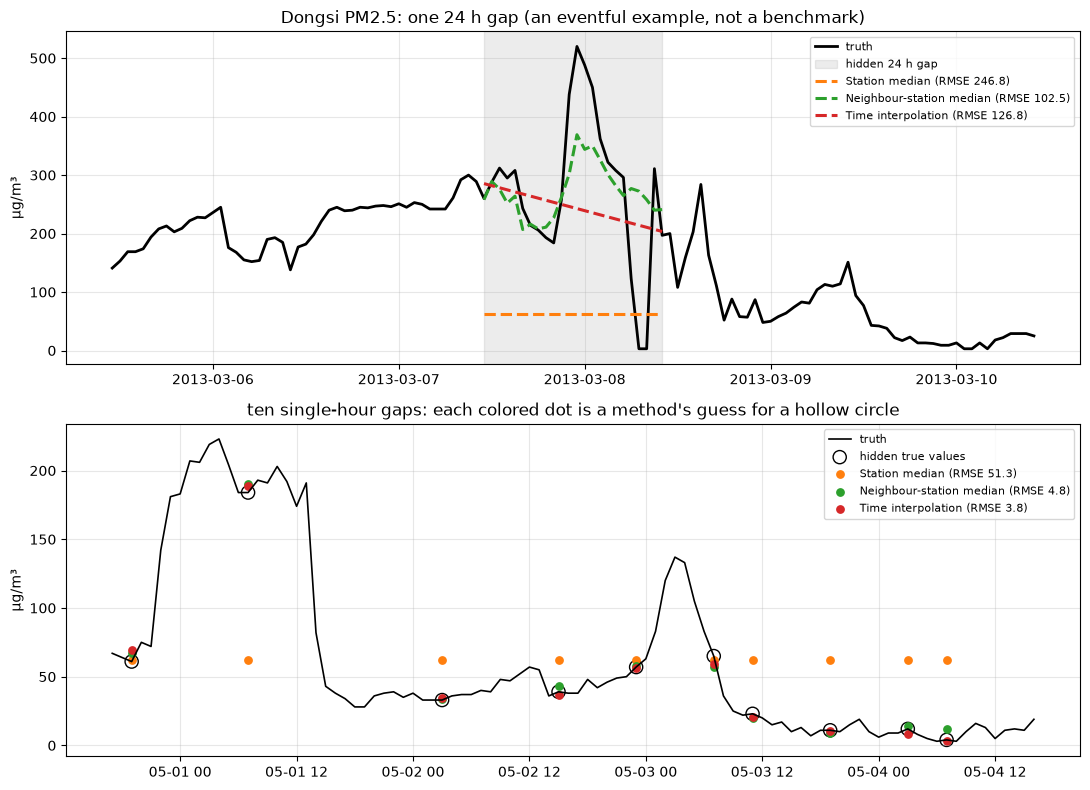

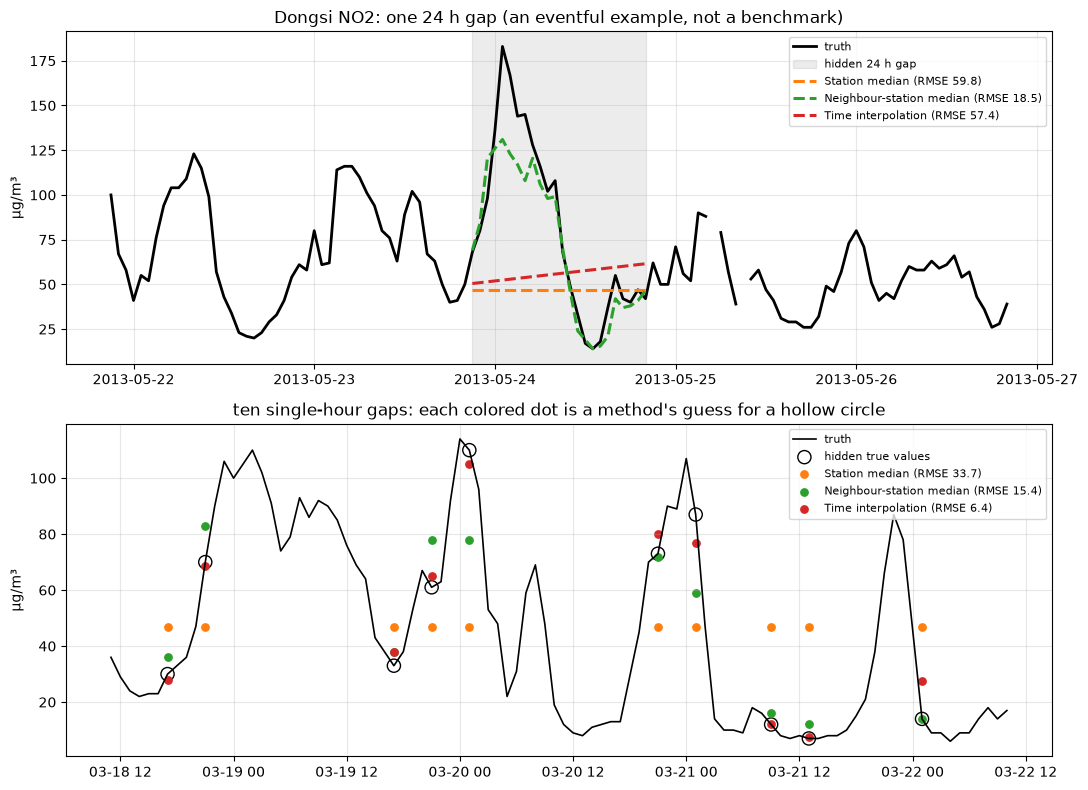

In [153]:
def plot_examples(pollutant="PM2.5", station="Dongsi", seed=3):
    pivot = build_pivot(pollutant)
    truth = pivot[station]
    r = np.random.default_rng(seed)
    ok = truth.notna().to_numpy()
    fig, axes = plt.subplots(2, 1, figsize=(11, 8))

    # (a) one 24 h gap, deliberately chosen (most variation of 300 random blocks) to contain an event
    full = pd.Series(ok.astype(int)).rolling(24).sum().eq(24).to_numpy()
    ends = [e for e in np.flatnonzero(full) if e - 24 >= 48 and e + 49 < len(truth) and ok[e - 24] and ok[e + 1]]
    ends = r.choice(ends, min(300, len(ends)), replace=False)
    end = max(ends, key=lambda e: truth.iloc[e - 23:e + 1].max() - truth.iloc[e - 23:e + 1].min())
    start = end - 23
    mask = np.zeros(len(truth), bool); mask[start:end + 1] = True
    preds = three_methods(pivot, station, mask)
    y = truth.to_numpy()[mask]
    ax = axes[0]; w = slice(start - 48, end + 49)
    ax.plot(truth.index[w], truth.iloc[w], color="black", lw=2, label="truth")
    ax.axvspan(truth.index[start], truth.index[end], color="grey", alpha=.15, label="hidden 24 h gap")
    for m, p in preds.items():
        seg = p.iloc[start:end + 1]
        rmse = np.sqrt(np.nanmean((seg.to_numpy() - y) ** 2))
        ax.plot(seg.index, seg, "--", lw=2.2, color=COLORS[m], label=f"{m} (RMSE {rmse:.1f})")
    ax.set_title(f"{station} {pollutant}: one 24 h gap (an eventful example, not a benchmark)")
    ax.set_ylabel("µg/m³"); ax.legend(fontsize=8)

    # (b) ten isolated single-hour gaps inside a 96 h window
    n = 96
    full = pd.Series(ok.astype(int)).rolling(n).sum().eq(n).to_numpy()
    e2 = r.choice(np.flatnonzero(full)); s2 = e2 - n + 1
    hide = r.choice(np.arange(s2 + 2, e2 - 1, 4), 10, replace=False)
    mask = np.zeros(len(truth), bool); mask[hide] = True
    preds = three_methods(pivot, station, mask)
    ax = axes[1]; w = slice(s2, e2 + 1)
    ax.plot(truth.index[w], truth.iloc[w], color="black", lw=1.2, label="truth")
    ax.scatter(truth.index[hide], truth.iloc[hide], s=90, facecolors="none", edgecolors="black", label="hidden true values")
    for m, p in preds.items():
        rmse = np.sqrt(np.nanmean((p.to_numpy()[hide] - truth.to_numpy()[hide]) ** 2))
        ax.scatter(truth.index[hide], p.iloc[hide], s=28, color=COLORS[m], label=f"{m} (RMSE {rmse:.1f})")
    ax.set_title("ten single-hour gaps: each colored dot is a method's guess for a hollow circle")
    ax.set_ylabel("µg/m³"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

plot_examples("PM2.5")
plot_examples("NO2")

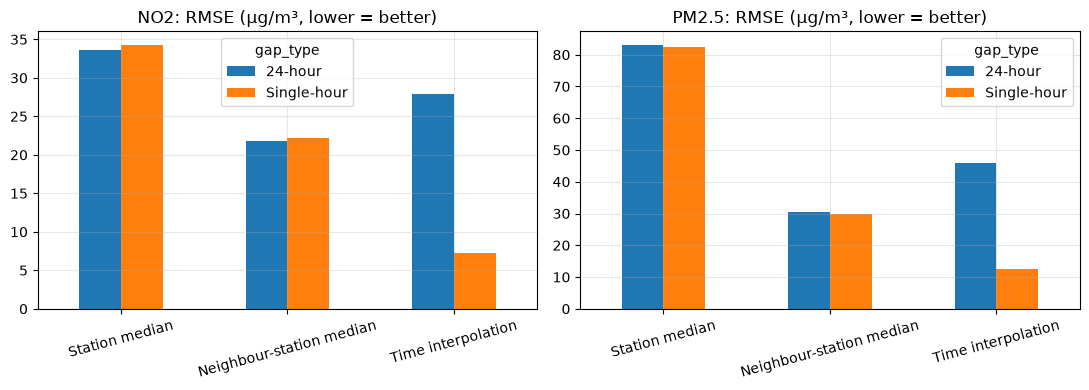

In [154]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pol in zip(axes, TARGET_POLLUTANTS):
    t = summary[summary["pollutant"] == pol].pivot(index="method", columns="gap_type", values="RMSE").loc[METHODS]
    t.plot.bar(ax=ax, rot=15)
    ax.set_title(f"{pol}: RMSE (µg/m³, lower = better)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

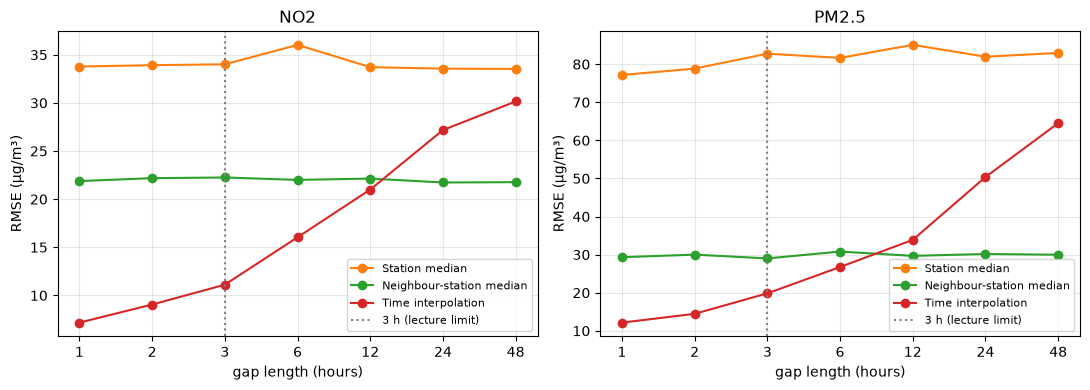

NO2


,Station median,Neighbour-station median,Time interpolation
gap (h),,,
1,33.78,21.88,7.17
2,33.92,22.18,9.05
3,34.01,22.25,11.11
6,36.03,22.00,16.04
12,33.71,22.14,21.00
24,33.56,21.73,27.18
48,33.53,21.76,30.15


PM2.5


,Station median,Neighbour-station median,Time interpolation
gap (h),,,
1,77.16,29.32,12.15
2,78.85,30.00,14.45
3,82.76,29.00,19.83
6,81.64,30.81,26.75
12,85.07,29.68,33.87
24,81.97,30.16,50.37
48,82.95,29.98,64.52


In [155]:
def rmse_vs_gap(pollutant, lengths=(1, 2, 3, 6, 12, 24, 48), n_events=150, seed=42):
    pivot = build_pivot(pollutant)
    rows = []
    for L in lengths:
        r = np.random.default_rng(seed + L)
        sq = dict.fromkeys(METHODS, 0.0); n = 0
        for station in pivot.columns:
            truth = pivot[station]
            mask = block_mask(truth, L, n_events, r)
            if not mask.any():
                continue
            preds = three_methods(pivot, station, mask, limit=None)
            y = truth.to_numpy()[mask]
            P = {m: p.to_numpy()[mask] for m, p in preds.items()}
            keep = np.all([~np.isnan(v) for v in P.values()], axis=0)   # same points for every method
            for m in METHODS:
                sq[m] += np.sum((P[m][keep] - y[keep]) ** 2)
            n += keep.sum()
        rows.append({"gap (h)": L, **{m: np.sqrt(sq[m] / n) for m in METHODS}})
    return pd.DataFrame(rows).set_index("gap (h)")

curves = {pol: rmse_vs_gap(pol) for pol in TARGET_POLLUTANTS}   # about a minute

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pol in zip(axes, TARGET_POLLUTANTS):
    c = curves[pol]
    for m in METHODS:
        ax.plot(range(len(c)), c[m], marker="o", color=COLORS[m], label=m)
    ax.axvline(list(c.index).index(3), ls=":", color="grey", label="3 h (lecture limit)")
    ax.set_xticks(range(len(c))); ax.set_xticklabels(c.index)
    ax.set_xlabel("gap length (hours)"); ax.set_ylabel("RMSE (µg/m³)"); ax.set_title(pol); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for pol, c in curves.items():
    print(pol); display(c.round(2))

The methods were evaluated using single-hour masks and 24-hour masks on the training data. RMSE and MAE were used to measure the accuracy of predictions on hidden observations.

For NO2, the best method for single-hour gaps was Time interpolation, while the best method for 24-hour gaps was Neighbour-station median. 
For PM2.5, the best method for single-hour gaps was Time interpolation, while the best method for 24-hour gaps was Neighbour-station median.

These results show whether short gaps are better handled using nearby time observations and whether longer gaps benefit from information from other stations or a station-level baseline. My final strategy for each gap length is based on the measured RMSE values.

## Task 4 · Outliers & transformations (10 pts)
Classify flagged points as **error** (stuck, impossible, code) vs **real episode** (e.g. Spring Festival fireworks, winter smog). Show at least one example of each on a time plot. Report skewness before/after your transform.

Number of PM2.5 outliers: 13511
Lower limit: -117.0
Upper limit: 251.0
Skewness before: 1.959
Skewness after log1p: -0.335


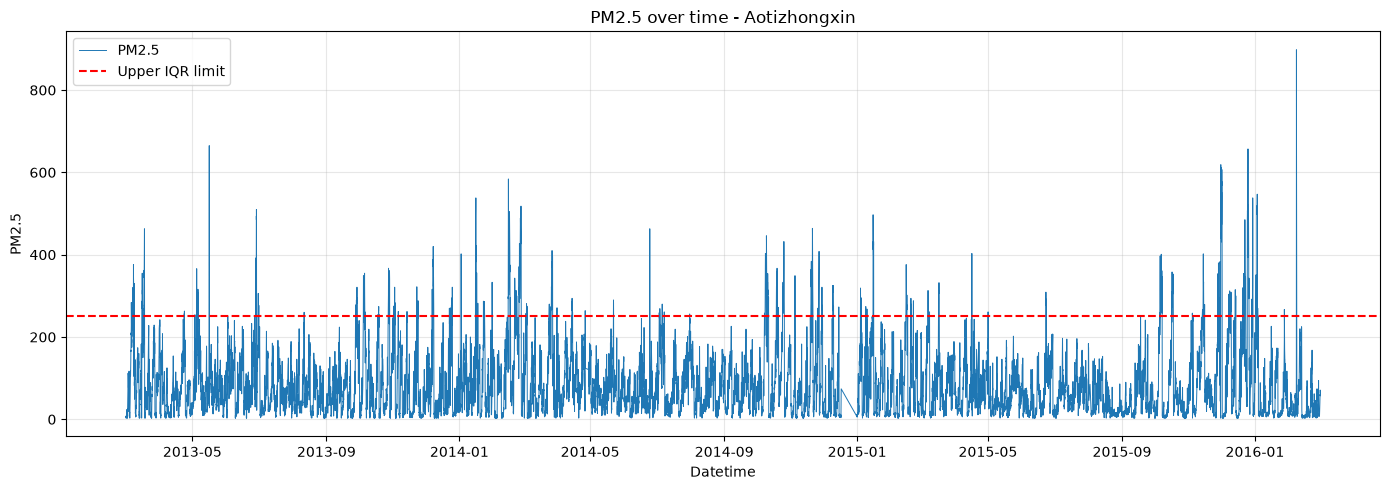

In [156]:
# TODOimport numpy as np
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select PM2.5 values
col = "PM2.5"

# Keep valid, non-missing, non-negative values
s = pd.to_numeric(df_clean[col], errors="coerce").dropna()
s = s[s >= 0]

# Detect outliers using the IQR method
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = s[(s < lower) | (s > upper)]

print("Number of PM2.5 outliers:", len(outliers))
print("Lower limit:", round(lower, 3))
print("Upper limit:", round(upper, 3))

# Compare skewness before and after log transformation
skew_before = s.skew()
s_log = np.log1p(s)
skew_after = s_log.skew()

print("Skewness before:", round(skew_before, 3))
print("Skewness after log1p:", round(skew_after, 3))

# Plot PM2.5 over time at one station
station_values = df_clean["station"].dropna()

if not station_values.empty:
    station = station_values.iloc[0]

    plot_df = df_clean[df_clean["station"] == station].copy()
    plot_df["datetime"] = pd.to_datetime(
        plot_df["datetime"], errors="coerce"
    )
    plot_df["PM2.5"] = pd.to_numeric(
        plot_df["PM2.5"], errors="coerce"
    )

    plot_df = plot_df.dropna(subset=["datetime", "PM2.5"])
    plot_df = plot_df[plot_df["PM2.5"] >= 0]
    plot_df = plot_df.sort_values("datetime")

    plt.figure(figsize=(14, 5))
    plt.plot(
        plot_df["datetime"],
        plot_df["PM2.5"],
        linewidth=0.7,
        label="PM2.5"
    )
    plt.axhline(
        upper,
        linestyle="--",
        color="red",
        label="Upper IQR limit"
    )

    plt.title(f"PM2.5 over time - {station}")
    plt.xlabel("Datetime")
    plt.ylabel("PM2.5")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No valid station values found.")

## Task 5 · Leak-free pipeline + TimeSeriesSplit CV (15 pts)
Use `add_features` and adapt `make_pipeline` (A10). Report 5-fold `TimeSeriesSplit` RMSE ± sd for the virtual sensor on `df_clean` (sorted by `datetime`). Try at least two preprocessing variants (e.g. with/without missing indicators, log-target via `TransformedTargetRegressor`).

In [157]:
data5 = add_features(df_clean.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
X5, y5 = data5[NUM_FEATS + CAT_FEATS], data5[TARGET]
# TODO: scores = cross_val_score(make_pipeline(...), X5, y5, cv=TimeSeriesSplit(5), scoring="neg_root_mean_squared_error", n_jobs=-1)

## Task 6 · Impact study — does data quality matter? (20 pts)
Train the **same model** two ways and score both on the **same complete-case rows of the test year**:
1. **Naive:** the merged export as-is (features built, rows with missing values dropped, raw labels).
2. **Yours:** `clean_basic` + your imputation + your pipeline.
Report RMSE, MAE, R², a predicted-vs-actual plot and the error by station. Explain the difference.

In [158]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
def scores(y, p): return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

test_f = add_features(test_year.drop(columns=["datetime"])).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])

# 1) naive baseline (provided)
naive = add_features(df).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])
naive_model = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=0)).fit(naive[NUM_FEATS + CAT_FEATS], naive[TARGET])
res_naive = scores(test_f[TARGET], naive_model.predict(test_f[NUM_FEATS + CAT_FEATS]))

# 2) yours — TODO: fit your pipeline on your cleaned + imputed training data, predict test_f
res_yours = {"RMSE": np.nan, "MAE": np.nan, "R2": np.nan}
pd.DataFrame({"naive (merged export)": res_naive, "yours (cleaned)": res_yours}).T.round(3)

,RMSE,MAE,R2
naive (merged export),37.212,22.251,0.796
yours (cleaned),NaN,NaN,NaN


## ★ HPC bonus (+10 pts) — parallel per-station cleaning
The 12 stations are independent: run `clean_basic` + your imputation **per station** with `joblib.Parallel` (or Dask) and compare wall-time for 1, 2, 4 … workers. Report the speed-up $S_p=T_1/T_p$, efficiency $E_p=S_p/p$ and the dominant step.

In [159]:
from joblib import Parallel, delayed
def clean_one_station(g):
    return clean_basic(g)            # TODO: + your imputation

groups = [g for _, g in df.groupby(df["station"].str.strip().str.title())]
# for p in [1, 2, 4, -1]:
#     t0 = time.perf_counter(); out = Parallel(n_jobs=p)(delayed(clean_one_station)(g) for g in groups)
#     print(p, time.perf_counter() - t0)

## Export for Lecture 2
Save your cleaned (and imputed) training years — it is the **input of the Week-2 AI Methods Shoot-out**.

In [160]:
# df_clean.drop(columns=["datetime"]).to_csv(f"beijing_clean_team{TEAM_ID}.csv.gz", index=False)

## Report template (1 page)
1. **Findings** — the issue log (dimension · station · column · period · problem · rows · fix · why).
2. **Key decisions** — imputation per gap length (Task 3 numbers), outlier policy, transforms, dropped rows and possible bias (MNAR in smog?).
3. **Impact** — naive vs cleaned test-year RMSE / MAE / R² and one plot.
4. **Lessons** — what would you ask the agency to change in how stations export data?
5. *(bonus)* HPC timings and speed-up.

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>